# 02. Декодирование METAR и качество погодных признаков

**Задача:** получить погодные поля из наблюдаемой части сообщения, сохранив
единицы, специальные коды и пропуски. Декодируем все 9 223 сообщения,
включая предшествующие сутки, и сохраняем 76 741 запись пилота.

Код, таблицы и графики выполнены. Наблюдение, тренд и примечания разделены.
Сведения о будущих попытках, итоговой ВПП и суточных экстремумах не становятся
погодными предикторами.

[Покрытие](01_metar_coverage.ipynb) ·
[Словарь полей](../reports/04_field_dictionary.md) ·
[Met Office — декодирование](https://docs.mavis.metoffice.gov.uk/guidance/metar-decode/) ·
[CAA CAP 746](https://www.caa.co.uk/publication/download/12602) ·
[python-metar](https://github.com/python-metar/python-metar)

## 1. Исходные данные и конфигурация декодирования METAR

Проверяем исходные SHA256. Версия `metar==2.0.1` зафиксирована.
Числовые поля еще не образуют утвержденный набор признаков модели.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
from importlib.metadata import version
from decode_metar import decode, split_sections, PARSER_VERSION
decode_manifest = json.loads((R/'04_decode_manifest.json').read_text(encoding='utf8'))
assert version('metar') == PARSER_VERSION == decode_manifest['parser_version']
assert sha(BASE/'scripts/decode_metar.py') == decode_manifest['decoder_sha256']
decoded = pd.read_parquet(DATA/'04_decoded_reports.parquet')
features = pd.read_parquet(DATA/'04_pilot_features.parquet')
assert len(decoded) == decode_manifest['raw_reports']
assert len(features) == manifest['rows'] and features.source_row.is_unique
assert int(features.GoA.sum()) == manifest['go_arounds']
display(pd.DataFrame([decode_manifest['environment']]))
display(pd.DataFrame([{
    'Сообщения':len(decoded), 'Без замечаний декодера':int(decoded.decoded_candidate.sum()),
    'С замечаниями':int((~decoded.decoded_candidate).sum()), 'Записи пилота':len(features),
    'GoA':int(features.GoA.sum()), 'Историческая доступность подтверждена':False}]))


,pandas,pyarrow,requests,metar
0,3.0.6,25.0.1,2.34.2,2.0.1


,Сообщения,Без замечаний декодера,С замечаниями,Записи пилота,GoA,Историческая доступность подтверждена
0,9223,9213,10,76741,307,False


## 2. Разделение наблюдаемых условий и прогностических групп

`TEMPO`, `BECMG`, `NOSIG` и временные индикаторы тренда отделяются до разбора.
RMK также хранится отдельно. В коде ниже видно, какая часть передается в
декодер. Полный текст источника сохраняется.

При неизвестных группах после QNH мы не восстанавливаем отсутствующее слово
TEMPO и не включаем эти группы в наблюдаемые явления и облака.
Полная реализация — [decode_metar.py](../scripts/decode_metar.py).

In [3]:
example = features.loc[features.trend_text.str.contains('BECMG',na=False)].iloc[0]
observation, trend, remarks = split_sections(example.metar)
readable_table(pd.DataFrame([{'Часть':'Наблюдение','Текст':observation},
    {'Часть':'Прогноз','Текст':trend},{'Часть':'Примечания','Текст':remarks}]))
parsed_example = decode(example.metar, example.airport, example.metar_utc.to_pydatetime())
display(pd.DataFrame([parsed_example])[[
    'wind_token','wind_speed_kt','wind_gust_kt','visibility_token','visibility_relation',
    'cloud_tokens','present_weather_tokens','qnh_hpa','parser_status']])


Часть,Текст
Наблюдение,EGCC 010750Z AUTO 29009KT 9999 BKN009 OVC024 09/07 Q1033
Прогноз,BECMG 35010KT FEW045
Примечания,


,wind_token,wind_speed_kt,wind_gust_kt,visibility_token,visibility_relation,cloud_tokens,present_weather_tokens,qnh_hpa,parser_status
0,29009KT,9.0,None,9999,ge,BKN009 OVC024,,1033.0,ok


## 3. Верификация декодирования METAR и целостности сопоставления

Для всех исходных сообщений повторяем декодирование и сравниваем поля с
сохраненной таблицей. После этого проверяем присоединение `many_to_one`:
одно сообщение может использоваться несколькими записями, но ни одна
строка исходного пилота не должна размножиться или исчезнуть.

In [4]:
reparsed = []
for row in decoded.itertuples(index=False):
    reparsed.append(decode(row.metar,row.station,row.metar_utc.to_pydatetime()))
reparsed = pd.DataFrame(reparsed).sort_values('metar_id').reset_index(drop=True)
saved = decoded.sort_values('metar_id').reset_index(drop=True)
pd.testing.assert_frame_equal(reparsed, saved[reparsed.columns], check_dtype=False)
links = pd.read_parquet(DATA/'03_pilot_matches.parquet')
right = decoded.rename(columns={'station':'airport'})
keys = ['airport','metar_utc','metar']
rejoined = links[['source_row','GoA']+keys].merge(right,
    on=keys,how='left',validate='many_to_one')
assert len(rejoined) == len(links) and rejoined.source_row.is_unique
assert int(rejoined.GoA.sum()) == int(links.GoA.sum())
cols = ['metar_id','wind_speed_kt','visibility_m','qnh_hpa','parser_status']
pd.testing.assert_frame_equal(rejoined.sort_values('source_row')[cols].reset_index(drop=True),
    features.sort_values('source_row')[cols].reset_index(drop=True),check_dtype=False)
display(Markdown(f'Повторно проверены **{len(decoded):,} сообщений** и '
    f'**{len(features):,} связей**. Расхождений нет.'))


Повторно проверены **9,223 сообщений** и **76,741 связей**. Расхождений нет.

## 4. Частота кодов и заполненность

В первой таблице знаменатель — число архивных сообщений; в графике
заполненности — число записей пилота. Это разные величины: сообщения
используются многократно.

Отсутствующий порыв не заменяется нулем. Отсутствие числового потолка может
означать CAVOK, отсутствие BKN/OVC, неизвестную высоту или неизвестное
количество облаков. Поэтому доля числовых значений не равна доле исправных
сообщений.

METAR  без_замечаний  CAVOK  VRB  порывы  тренд  COR
station archive_month                                                      
EGCC    2019-01         1535           1534      9  462      46   1060    6
        2019-07         1536           1536     19  369       5    476    2
EGLL    2019-01         1535           1534      2  187      24   1201    6
        2019-07         1536           1536      4  103      21    445    2
LFPG    2019-01         1544           1536    212   42      12   1543    0
        2019-07         1537           1537   1116   93      35   1537    0

Скорость ветра  Переданный порыв  Видимость / граница  \
airport month                                                            
EGCC    2019-01           100.0              2.89                100.0   
        2019-07           100.0              0.43                100.0   
EGLL    2019-01           100.0              2.23                100.0   
        2019-07           100.0              1.83                100.0   
LFPG    2019-01           100.0              1.07                100.0   
        2019-07           100.0              2.84                100.0   

                 Числовая база BKN/OVC  Температура  Точка росы     QNH  
airport month                                                            
EGCC    2019-01                  66.60       100.00      100.00  100.00  
        2019-07                  35.16       100.00      100.00  100.00  
EGLL    2019-01                  52.98       100.00      100.00  100.00  
        2019-07                  24.44       100.00      100.00  100.00  
LFPG    2019-01                  75.41        99.93       99.93   99.93  
        2019-07                  17.20       100.00      100.00  100.00

station,metar_utc,metar,temperature_c,dewpoint_c,qnh_hpa,parser_status
LFPG,2019-01-07 19:00:00+00:00,LFPG 071900Z 23010KT 8000 FEW007 BKN024 TEMPO BKN007,NaN,NaN,NaN,needs_review


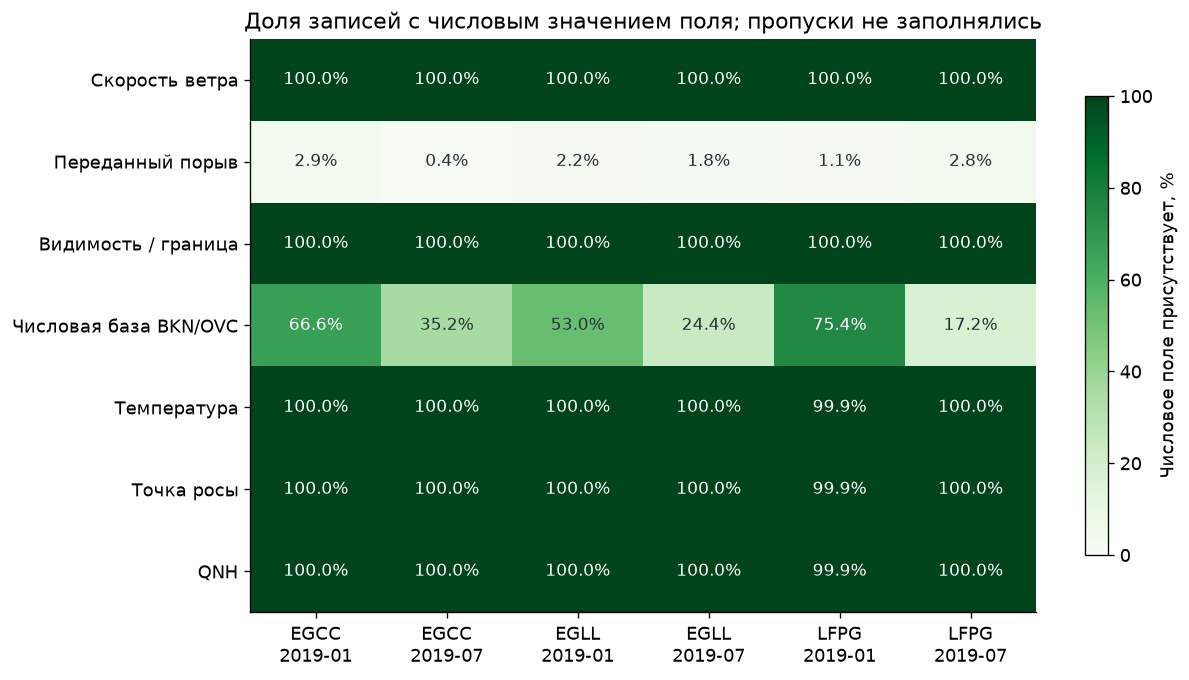

In [5]:
report_counts = decoded.groupby(['station','archive_month']).agg(
    METAR=('metar_id','size'), без_замечаний=('decoded_candidate','sum'),
    CAVOK=('cavok','sum'), VRB=('wind_variable','sum'), порывы=('gust_group_reported','sum'),
    тренд=('has_trend','sum'), COR=('correction_reported','sum'))
display(report_counts)
labels = {'wind_speed_kt':'Скорость ветра','wind_gust_kt':'Переданный порыв',
    'visibility_m':'Видимость / граница','cloud_ceiling_ft':'Числовая база BKN/OVC',
    'temperature_c':'Температура','dewpoint_c':'Точка росы','qnh_hpa':'QNH'}
presence = features.groupby(['airport','month'])[list(labels)].agg(lambda x:100*x.notna().mean())
presence.columns = [labels[x] for x in presence.columns]
display(presence.round(2))
core_missing = decoded.loc[decoded.temperature_token.isna() | decoded.qnh_token.isna(),
    ['station','metar_utc','metar','temperature_c','dewpoint_c','qnh_hpa','parser_status']]
readable_table(core_missing)
fig, ax = plt.subplots(figsize=(10.5,5.8))
matrix = presence.T
im = ax.imshow(matrix,cmap='Greens',vmin=0,vmax=100,aspect='auto')
ax.set_yticks(range(len(matrix)),matrix.index)
ax.set_xticks(range(len(matrix.columns)),[f'{a}\n{m}' for a,m in matrix.columns])
ax.grid(False)
for i in range(len(matrix)):
    for j in range(len(matrix.columns)):
        v = matrix.iloc[i,j]
        ax.text(j,i,f'{v:.1f}%',ha='center',va='center',color='white' if v>55 else '#263238',fontsize=10)
ax.set_title('Доля записей с числовым значением поля; пропуски не заполнялись')
fig.colorbar(im,ax=ax,label='Числовое поле присутствует, %',shrink=.8)
save('04_field_presence')


## 5. Наблюдаемые распределения

Показываем все записи пилота; это описание данных, без причинного вывода
о GoA. Верхняя граница измеренной видимости не восстанавливается:
9999 и CAVOK представлены отдельными кодовыми категориями.
Диапазоны — диагностика, не правила очистки.

,field,count,missing,minimum,maximum
0,wind_speed_kt,76741,0,0.0,23.0
1,wind_gust_kt,1494,75247,16.0,40.0
2,visibility_m,76741,0,50.0,10000.0
3,cloud_ceiling_ft,30858,45883,100.0,26000.0
4,temperature_c,76732,9,-5.0,41.0
5,dewpoint_c,76732,9,-7.0,22.0
6,qnh_hpa,76732,9,983.0,1045.0


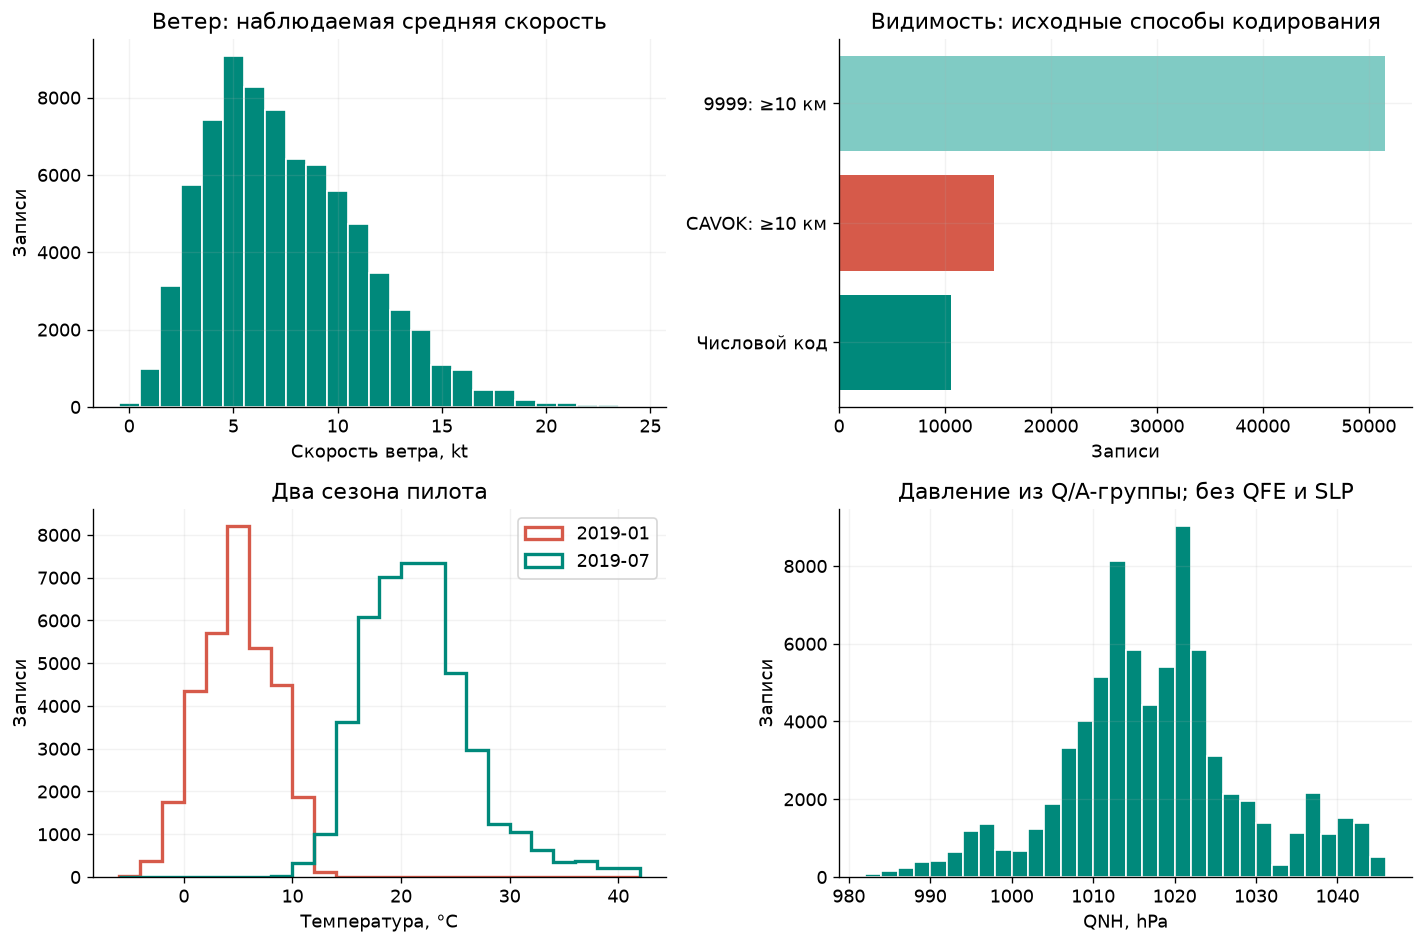

In [6]:
display(pd.read_csv(R/'04_numeric_ranges.csv'))
fig, axes = plt.subplots(2,2,figsize=(12,8))
axes[0,0].hist(features.wind_speed_kt.dropna(),bins=np.arange(-.5,25.5,1),color=GREEN,edgecolor='white')
axes[0,0].set(xlabel='Скорость ветра, kt',ylabel='Записи',title='Ветер: наблюдаемая средняя скорость')
v = pd.Series(np.select([features.cavok.eq(True),features.visibility_token.eq('9999'),
    features.visibility_relation.eq('lt'),features.visibility_relation.eq('eq')],
    ['CAVOK: ≥10 км','9999: ≥10 км','0000: <50 м','Числовой код'],default='Пропуск / другое')).value_counts()
axes[0,1].barh(v.index[::-1],v.values[::-1],color=[GREEN,CORAL,LIGHT_GREEN,LIGHT_CORAL][:len(v)])
axes[0,1].set(xlabel='Записи',title='Видимость: исходные способы кодирования')
for month,color in [('2019-01',CORAL),('2019-07',GREEN)]:
    axes[1,0].hist(features.loc[features.month.eq(month),'temperature_c'].dropna(),
        bins=np.arange(-6,44,2),histtype='step',lw=2,color=color,label=month)
axes[1,0].set(xlabel='Температура, °C',ylabel='Записи',title='Два сезона пилота')
axes[1,0].legend()
axes[1,1].hist(features.qnh_hpa.dropna(),bins=np.arange(982,1048,2),color=GREEN,edgecolor='white')
axes[1,1].set(xlabel='QNH, hPa',ylabel='Записи',title='Давление из Q/A-группы; без QFE и SLP')
save('05_weather_distributions')


## 6. Интерпретация облачных групп и кодов отсутствующих значений

`//////CB` и `//////TCU` передают тип облака при неизвестных количестве и
высоте (CAP 746, 4.149–4.150). В `SCT020///` известны количество и база,
а тип неизвестен (4.147). Эти коды сохранены.

`BKN000` означает базу ниже 100 ft (4.109): число 100 используется только
вместе с отношением `lt`. Для остальных баз сохраняется переданная ступень
кода, а не более точное измерение. Все высоты здесь относительно аэродрома.
VV хранится отдельно от базы BKN/OVC; CAVOK не превращается в бесконечный
потолок.

cloud_state,NCD,NSC,cavok,layers
airport,,,,
EGCC,2431,40,86,7231
EGLL,16300,145,52,18240
LFPG,0,577,14461,17178


,неизвестен_тип,неизвестно_количество,передана_VV
airport,,,
EGCC,564,670,24
EGLL,1125,1236,0
LFPG,0,0,145


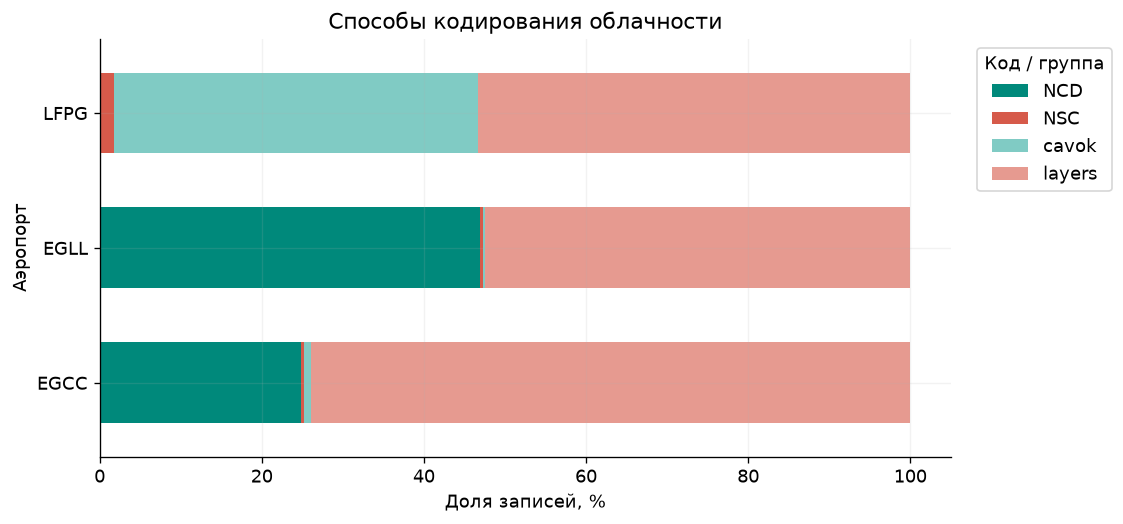

In [7]:
clouds = features.groupby(['airport','cloud_state']).size().unstack(fill_value=0)
display(clouds)
unknown = features.groupby('airport').agg(
    неизвестен_тип=('cloud_type_unavailable','sum'),
    неизвестно_количество=('cloud_amount_unavailable','sum'),
    передана_VV=('vertical_visibility_reported','sum'))
display(unknown)
fig, ax = plt.subplots(figsize=(9.5,4.5))
clouds.div(clouds.sum(axis=1),axis=0).mul(100).plot.barh(stacked=True,ax=ax,
    color=[GREEN,CORAL,LIGHT_GREEN,LIGHT_CORAL,'#90A4AE','#546E7A'],width=.6)
ax.set(xlabel='Доля записей, %',ylabel='Аэропорт',title='Способы кодирования облачности')
ax.legend(title='Код / группа',bbox_to_anchor=(1.02,1),loc='upper left')
save('06_cloud_coding')


## 7. Примеры преобразования сообщений METAR в погодные признаки

Для каждой категории выбран первый по C40 пример, без отбора по исходу.
Возраст показывает сопоставление во времени, а не подтвержденную задержку
передачи. Исходная строка и прогноз показаны рядом с декодированными полями.

In [8]:
examples = pd.read_csv(R/'04_examples.csv',keep_default_na=False)
names = {'COR':'Исправление COR','CAVOK':'CAVOK','VRB':'Переменный ветер VRB',
    'gust':'Переданный порыв','direction_variation':'Диапазон направления',
    'trend_TEMPO':'Тренд TEMPO','trend_BECMG':'Тренд BECMG',
    'midnight_transition':'Переход суток UTC','reduced_visibility':'Сниженная видимость',
    'vertical_visibility':'Вертикальная видимость','recent_weather':'Недавнее явление RE',
    'automatic_cloud_unknowns':'Автоматическая группа с неизвестными количеством / высотой',
    'cloud_below_100ft':'База облака ниже 100 ft'}
for row in examples.itertuples(index=False):
    display(Markdown(f'### {names[row.category]} — {row.airport}'))
    display(HTML('<pre style="white-space:pre-wrap;overflow-wrap:anywhere;padding:10px">'+escape(row.metar)+'</pre>'))
    values = [('C40 UTC',row.c40_utc),('METAR UTC',row.metar_utc),('Давность, мин',round(row.age_minutes,2)),
        ('Наблюдаемая часть',row.observed_text),('Прогноз',row.trend_text or 'Не передан'),
        ('Ветер',row.wind_token),('Скорость / переданный порыв, kt',f'{row.wind_speed_kt} / {row.wind_gust_kt}'),
        ('Видимость: код / значение / отношение',f'{row.visibility_token} / {row.visibility_m} / {row.visibility_relation}'),
        ('Облака',row.cloud_tokens),('База BKN/OVC: значение / отношение',f'{row.cloud_ceiling_ft} / {row.cloud_ceiling_relation}'),
        ('Наблюдаемые явления',row.present_weather_tokens or 'Группа не передана'),
        ('Недавние явления',row.recent_weather_tokens or 'Группа не передана'),('QNH, hPa',row.qnh_hpa)]
    readable_table(pd.DataFrame(values,columns=['Поле','Значение']))


### Исправление COR — EGLL

Поле,Значение
C40 UTC,2019-01-17T06:21:52+00:00
METAR UTC,2019-01-17T06:20:00+00:00
"Давность, мин",1.87
Наблюдаемая часть,COR EGLL 170620Z AUTO 29008KT 9999 SCT036 04/02 Q1006
Прогноз,TEMPO SHRA
Ветер,29008KT
"Скорость / переданный порыв, kt",8.0 /
Видимость: код / значение / отношение,9999 / 10000.0 / ge
Облака,SCT036
База BKN/OVC: значение / отношение,/ missing


### CAVOK — LFPG

Поле,Значение
C40 UTC,2019-01-02T17:09:44+00:00
METAR UTC,2019-01-02T17:00:00+00:00
"Давность, мин",9.73
Наблюдаемая часть,LFPG 021700Z 36007KT CAVOK 06/01 Q1040
Прогноз,NOSIG
Ветер,36007KT
"Скорость / переданный порыв, kt",7.0 /
Видимость: код / значение / отношение,CAVOK / 10000.0 / ge
Облака,
База BKN/OVC: значение / отношение,/ missing


### Переменный ветер VRB — EGLL

...

Поле,Значение
C40 UTC,2019-01-06T14:27:22+00:00
METAR UTC,2019-01-06T14:20:00+00:00
"Давность, мин",7.37
Наблюдаемая часть,EGCC 061420Z VRB02KT 3000 -RADZ FEW004 SCT012 BKN018 07/06 Q1037 REDZ
Прогноз,Не передан
Ветер,VRB02KT
"Скорость / переданный порыв, kt",2.0 /
Видимость: код / значение / отношение,3000 / 3000.0 / eq
Облака,FEW004 SCT012 BKN018
База BKN/OVC: значение / отношение,1800.0 / reported_step


### Автоматическая группа с неизвестными количеством / высотой — EGCC

Поле,Значение
C40 UTC,2019-01-13T14:21:43+00:00
METAR UTC,2019-01-13T14:20:00+00:00
"Давность, мин",1.72
Наблюдаемая часть,EGCC 131420Z AUTO 27020G33KT 9999 -RA BKN012/// BKN017/// //////TCU 10/07 Q1010
Прогноз,Не передан
Ветер,27020G33KT
"Скорость / переданный порыв, kt",20.0 / 33.0
Видимость: код / значение / отношение,9999 / 10000.0 / ge
Облака,BKN012/// BKN017/// //////TCU
База BKN/OVC: значение / отношение,/ missing


### База облака ниже 100 ft — LFPG

Поле,Значение
C40 UTC,2019-01-22T18:30:27+00:00
METAR UTC,2019-01-22T18:30:00+00:00
"Давность, мин",0.45
Наблюдаемая часть,LFPG 221830Z 19010KT 2000 R08R/1200N BR BKN000 BKN001 01/01 Q1002 R88/CLRD//
Прогноз,NOSIG
Ветер,19010KT
"Скорость / переданный порыв, kt",10.0 /
Видимость: код / значение / отношение,2000 / 2000.0 / eq
Облака,BKN000 BKN001
База BKN/OVC: значение / отношение,100.0 / lt


## 8. Классификация сообщений с замечаниями и связанных записей

После поддержки документированных автоматических облачных кодов осталось
10 сообщений с замечаниями, затрагивающих 81 запись и 3 GoA.
Ни одна запись не удалена. Флаг `weather_candidate_60min` — осторожный
диагностический сценарий, не принятое исключение из основной базы.

Разные причины не смешиваем: неподдержанная группа состояния ВПП не
доказывает ошибочность основных погодных значений; пропущенный индикатор
тренда не восстанавливаем по догадке. Текст из источника остается исходным.

In [9]:
residuals = pd.read_csv(R/'04_decode_residuals.csv',keep_default_na=False)
reason_names = {'unsupported_runway_state_group':'Не поддержана группа состояния ВПП',
    'unlabelled_weather_after_qnh':'Погодные группы после QNH без индикатора тренда',
    'unclassified_five_slashes':'Не классифицирована группа /////',
    'temperature_and_qnh_absent':'Отсутствуют температура и QNH'}
residuals['Причина'] = residuals.audit_category.map(reason_names)
residual_summary = residuals.groupby('Причина').agg(
    Сообщения=('metar_id','size'), Записи=('matched_rows','sum'), GoA=('matched_go_arounds','sum'))
display(residual_summary)
readable_table(residuals[['station','metar_utc','Причина','matched_rows','matched_go_arounds']])
for row in residuals.itertuples(index=False):
    display(Markdown(f'**{row.station}, {row.metar_utc}** — {reason_names[row.audit_category]}; '
                     f'записи: {row.matched_rows}, GoA: {row.matched_go_arounds}.'))
    display(HTML('<pre style="white-space:pre-wrap;overflow-wrap:anywhere;padding:8px">'+escape(row.metar)+'</pre>'))


,Сообщения,Записи,GoA
Причина,,,
Не классифицирована группа /////,2,2,0
Не поддержана группа состояния ВПП,5,60,3
Отсутствуют температура и QNH,1,9,0
Погодные группы после QNH без индикатора тренда,2,10,0


station,metar_utc,Причина,matched_rows,matched_go_arounds
EGCC,2019-01-22 10:50:00+00:00,Погодные группы после QNH без индикатора тренда,6,0
EGLL,2019-01-16 15:20:00+00:00,Погодные группы после QNH без индикатора тренда,4,0
LFPG,2019-01-07 19:00:00+00:00,Отсутствуют температура и QNH,9,0
LFPG,2019-01-30 00:30:00+00:00,Не классифицирована группа /////,0,0
LFPG,2019-01-30 03:00:00+00:00,Не классифицирована группа /////,2,0
LFPG,2019-01-30 04:00:00+00:00,Не поддержана группа состояния ВПП,12,3
LFPG,2019-01-30 04:30:00+00:00,Не поддержана группа состояния ВПП,9,0
LFPG,2019-01-30 05:00:00+00:00,Не поддержана группа состояния ВПП,12,0
LFPG,2019-01-30 05:30:00+00:00,Не поддержана группа состояния ВПП,14,0
LFPG,2019-01-30 06:00:00+00:00,Не поддержана группа состояния ВПП,13,0


**EGCC, 2019-01-22 10:50:00+00:00** — Погодные группы после QNH без индикатора тренда; записи: 6, GoA: 0.

**EGLL, 2019-01-16 15:20:00+00:00** — Погодные группы после QNH без индикатора тренда; записи: 4, GoA: 0.

**LFPG, 2019-01-07 19:00:00+00:00** — Отсутствуют температура и QNH; записи: 9, GoA: 0.

...

**LFPG, 2019-01-30 04:00:00+00:00** — Не поддержана группа состояния ВПП; записи: 12, GoA: 3.

**LFPG, 2019-01-30 04:30:00+00:00** — Не поддержана группа состояния ВПП; записи: 9, GoA: 0.

**LFPG, 2019-01-30 05:00:00+00:00** — Не поддержана группа состояния ВПП; записи: 12, GoA: 0.

**LFPG, 2019-01-30 05:30:00+00:00** — Не поддержана группа состояния ВПП; записи: 14, GoA: 0.

**LFPG, 2019-01-30 06:00:00+00:00** — Не поддержана группа состояния ВПП; записи: 13, GoA: 0.

## 9. Диагностические сценарии и проверки семантики

Сравниваем число записей с сообщением, число записей без замечаний декодера
и более осторожный вариант без COR. Это не новое формирование обучающей
выборки. Даже вариант без COR не доказывает историческую доступность.

Тесты проверяют отделение прогнозных групп, цензурированную видимость,
неизвестные облака, порывы, отрицательные температуры, давление и сохранение
неподдержанных групп как замечаний.

,Сценарий,Записи,GoA,"Доля записей, %"
0,Есть METAR до 60 минут,76741,307,100.000
1,Без замечаний декодера,76660,304,99.894
2,Без замечаний и без COR,76523,303,99.716


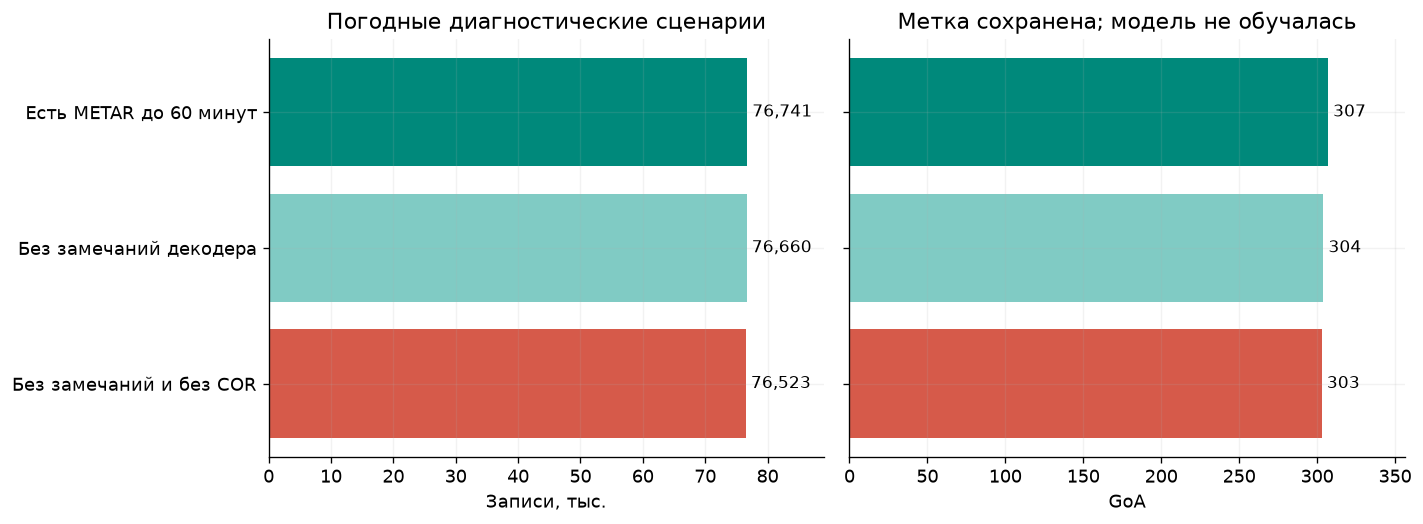

In [10]:
scenario_rows = []
for name,mask in [('Есть METAR до 60 минут',features.status.eq('matched')),
    ('Без замечаний декодера',features.weather_candidate_60min),
    ('Без замечаний и без COR',features.weather_candidate_60min_without_cor)]:
    scenario_rows.append({'Сценарий':name,'Записи':int(mask.sum()),
        'GoA':int(features.loc[mask,'GoA'].sum()),'Доля записей, %':100*mask.mean()})
scenarios = pd.DataFrame(scenario_rows)
display(scenarios.round(3))
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
axes[0].barh(scenarios['Сценарий'][::-1],scenarios['Записи'][::-1],color=[CORAL,LIGHT_GREEN,GREEN])
axes[0].set(xlabel='Записи',title='Погодные диагностические сценарии')
for i,n in enumerate(scenarios['Записи'][::-1]):
    axes[0].text(n,i,f' {n:,}',va='center',fontsize=10)
axes[0].set_xlim(0,len(features)*1.16)
from matplotlib.ticker import FuncFormatter
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x/1000:.0f}'))
axes[0].set_xlabel('Записи, тыс.')
axes[1].barh(scenarios['Сценарий'][::-1],scenarios['GoA'][::-1],color=[CORAL,LIGHT_GREEN,GREEN])
axes[1].set(xlabel='GoA',title='Метка сохранена; модель не обучалась')
axes[1].set_yticklabels([])
for i,n in enumerate(scenarios['GoA'][::-1]):
    axes[1].text(n,i,f' {n}',va='center',fontsize=10)
axes[1].set_xlim(0,manifest['go_arounds']*1.16)
save('07_decode_scenarios')


In [11]:
import unittest
import test_decode_metar
suite = unittest.defaultTestLoader.loadTestsFromModule(test_decode_metar)
outcome = unittest.TextTestRunner(verbosity=2,stream=sys.stdout).run(suite)
assert outcome.wasSuccessful()
display(Markdown('**Итог:** погодные поля и остаточные замечания сохранены; '
    'строки и исходные значения не удалялись. Историческая доступность '
    'сообщений и целевого аэропорта остается ограничением. Обучение и '
    'масштабирование на всю базу еще не выполнялись.'))


test_automatic_cloud_unknowns_are_preserved (test_decode_metar.DecodeSemantics.test_automatic_cloud_unknowns_are_preserved) ... 

ok


test_cavok_and_censored_visibility (test_decode_metar.DecodeSemantics.test_cavok_and_censored_visibility) ... 

ok


test_cloud_zero_code_is_a_bound (test_decode_metar.DecodeSemantics.test_cloud_zero_code_is_a_bound) ... 

...

ok


test_unrecognized_groups_are_audited (test_decode_metar.DecodeSemantics.test_unrecognized_groups_are_audited) ... 

ok


----------------------------------------------------------------------
Ran 12 tests in 0.014s

OK


**Итог:** погодные поля и остаточные замечания сохранены; строки и исходные значения не удалялись. Историческая доступность сообщений и целевого аэропорта остается ограничением. Обучение и масштабирование на всю базу еще не выполнялись.